# Воронка маркетплейса: от поиска до покупки

Разбираю путь сессии от отправки поискового запроса до завершённой покупки. Задача — увидеть, на каком этапе теряется больше всего сессий, и сравнить конверсию на мобильных устройствах и десктопе.

Дополнительно смотрю на различия между каналами привлечения и категориями товаров.

**Данные:** синтетические, подготовлены для учебного кейса. Это не данные реального маркетплейса.

**Единица анализа:** сессия. У одного пользователя может быть несколько сессий.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sessions = pd.read_csv(ROOT / "data/sessions.csv", parse_dates=["session_start"])
events = pd.read_csv(ROOT / "data/events.csv", parse_dates=["event_time"])
print(f"Сессий: {sessions.session_id.nunique():,}")
print(f"Пользователей: {sessions.user_id.nunique():,}")
print(f"Событий: {len(events):,}")
sessions.head()

Сессий: 4,200
Пользователей: 2,111
Событий: 8,927


,session_id,user_id,session_start,device,acquisition_channel,user_type,category,search_results_count
0,S000001,MU00170,2025-05-02 10:33:00,Desktop,Social,New,Electronics,7
1,S000002,MU00948,2025-04-24 10:24:00,Mobile,Organic,New,Electronics,15
2,S000003,MU01213,2025-04-21 09:50:00,Mobile,Direct,Returning,Electronics,13
3,S000004,MU01210,2025-04-18 13:43:00,Desktop,Organic,New,Sports,13
4,S000005,MU00622,2025-05-12 09:09:00,Mobile,Organic,New,Beauty,6


## Проверка исходных таблиц

Проверяю состав и полноту таблиц, уникальность `session_id` и `event_id`, а также связь событий с известными сессиями. После этого можно переходить к расчёту воронки.


In [2]:
print("Дубликаты session_id:", sessions.session_id.duplicated().sum())
print("Дубликаты event_id:", events.event_id.duplicated().sum())
print("События без известной сессии:", (~events.session_id.isin(sessions.session_id)).sum())
print("Пропуски в sessions:")
display(sessions.isna().sum())
print("События:")
display(events.event_name.value_counts())

Дубликаты session_id: 0
Дубликаты event_id: 0
События без известной сессии: 0
Пропуски в sessions:


session_id              0
user_id                 0
session_start           0
device                  0
acquisition_channel     0
user_type               0
category                0
search_results_count    0
dtype: int64

События:


event_name
search_submitted      4200
product_viewed        2994
add_to_cart            850
checkout_started       532
purchase_completed     351
Name: count, dtype: int64

## Воронка от поиска до покупки

Для каждого шага считаю число уникальных сессий, в которых произошло соответствующее событие: поиск → просмотр товара → добавление в корзину → начало оформления → покупка.

Конверсию показываю и относительно исходного числа сессий, и относительно предыдущего шага.


In [3]:
event_order = [
    ("search_submitted", "Поиск"),
    ("product_viewed", "Просмотр товара"),
    ("add_to_cart", "Добавление в корзину"),
    ("checkout_started", "Начало оформления"),
    ("purchase_completed", "Покупка"),
]
funnel = pd.DataFrame([
    {"event_name": name, "step": label, "sessions": events.loc[events.event_name.eq(name), "session_id"].nunique()}
    for name, label in event_order
])
funnel["conversion_from_search"] = funnel.sessions / sessions.session_id.nunique()
funnel["conversion_from_previous"] = funnel.sessions / funnel.sessions.shift(1)
funnel.loc[0, "conversion_from_previous"] = 1.0
display(funnel)

,event_name,step,sessions,conversion_from_search,conversion_from_previous
0,search_submitted,Поиск,4200,1.000000,1.000000
1,product_viewed,Просмотр товара,2994,0.712857,0.712857
2,add_to_cart,Добавление в корзину,850,0.202381,0.283901
3,checkout_started,Начало оформления,532,0.126667,0.625882
4,purchase_completed,Покупка,351,0.083571,0.659774


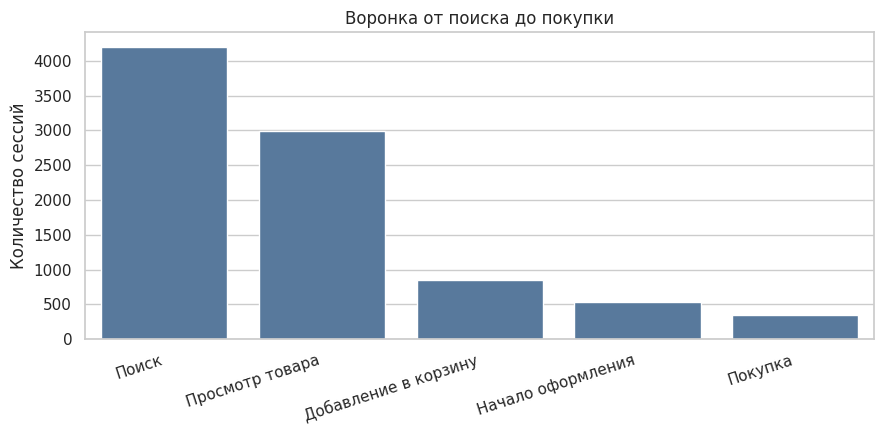

In [4]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=funnel, x="step", y="sessions", color="#4C78A8")
plt.xticks(rotation=18, ha="right")
plt.ylabel("Количество сессий")
plt.xlabel("")
plt.title("Воронка от поиска до покупки")
plt.tight_layout(); plt.show()

## На каком шаге теряется больше всего сессий

Сравниваю абсолютное число потерянных сессий и долю от предыдущего шага. Большая абсолютная потеря помогает определить участок для первоочередной проверки, но сама по себе не объясняет причину отказа.


In [5]:
funnel["lost_sessions"] = funnel.sessions.shift(1) - funnel.sessions
funnel["lost_share_from_previous"] = funnel.lost_sessions / funnel.sessions.shift(1)
display(funnel[["step", "sessions", "conversion_from_previous", "lost_sessions", "lost_share_from_previous"]])
losses = funnel.dropna(subset=["lost_sessions"]).sort_values("lost_sessions", ascending=False)
worst_step = losses.iloc[0]
print(f"Наибольшая абсолютная потеря: перед шагом «{worst_step.step}» — {int(worst_step.lost_sessions)} сессий.")

,step,sessions,conversion_from_previous,lost_sessions,lost_share_from_previous
0,Поиск,4200,1.000000,NaN,NaN
1,Просмотр товара,2994,0.712857,1206.0,0.287143
2,Добавление в корзину,850,0.283901,2144.0,0.716099
3,Начало оформления,532,0.625882,318.0,0.374118
4,Покупка,351,0.659774,181.0,0.340226


Наибольшая абсолютная потеря: перед шагом «Добавление в корзину» — 2144 сессий.


## Мобильные устройства и десктоп

Для каждой сессии отмечаю, были ли просмотр товара, добавление в корзину, начало оформления и покупка. Затем сравниваю конверсию сессий в покупку по типу устройства.


In [6]:
session_flags = sessions[["session_id", "device", "acquisition_channel", "user_type", "category", "search_results_count"]].copy()
for event_name, col in [("product_viewed", "viewed"), ("add_to_cart", "added_to_cart"), ("checkout_started", "checkout_started"), ("purchase_completed", "purchased")]:
    ids = set(events.loc[events.event_name.eq(event_name), "session_id"])
    session_flags[col] = session_flags.session_id.isin(ids)
device_metrics = session_flags.groupby("device", as_index=False).agg(
    sessions=("session_id", "count"),
    view_rate=("viewed", "mean"),
    cart_rate=("added_to_cart", "mean"),
    purchase_conversion=("purchased", "mean")
)
display(device_metrics)

,device,sessions,view_rate,cart_rate,purchase_conversion
0,Desktop,1190,0.769748,0.242857,0.118487
1,Mobile,3010,0.690365,0.186379,0.069767


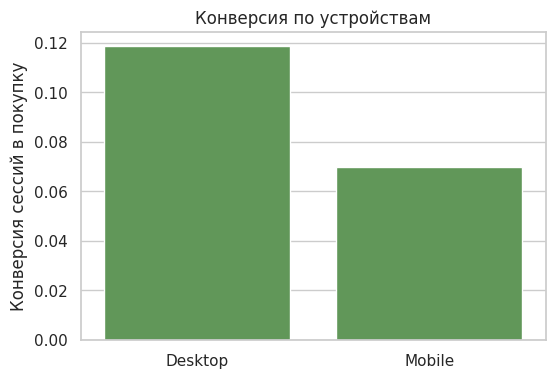

In [7]:
plt.figure(figsize=(6, 4))
sns.barplot(data=device_metrics, x="device", y="purchase_conversion", color="#59A14F")
plt.ylabel("Конверсия сессий в покупку")
plt.xlabel("")
plt.title("Конверсия по устройствам")
plt.show()

## Каналы привлечения и категории

Сравниваю долю сессий с покупкой по каналам привлечения и категориям товаров. Результаты описывают различия в этой выборке; для объяснения причин понадобятся дополнительные данные о пользователях, ассортименте и пользовательском опыте.


In [8]:
channel_metrics = session_flags.groupby("acquisition_channel", as_index=False).agg(
    sessions=("session_id", "count"), purchase_conversion=("purchased", "mean")
).sort_values("purchase_conversion", ascending=False)
category_metrics = session_flags.groupby("category", as_index=False).agg(
    sessions=("session_id", "count"), purchase_conversion=("purchased", "mean")
).sort_values("purchase_conversion", ascending=False)
print("По каналам:"); display(channel_metrics)
print("По категориям:"); display(category_metrics)

По каналам:


,acquisition_channel,sessions,purchase_conversion
1,Organic,1315,0.089734
2,Paid Search,1344,0.084821
0,Direct,699,0.078684
3,Social,842,0.076010


По категориям:


,category,sessions,purchase_conversion
3,Home,822,0.090024
4,Sports,643,0.088647
2,Fashion,1040,0.083654
1,Electronics,952,0.079832
0,Beauty,743,0.076716


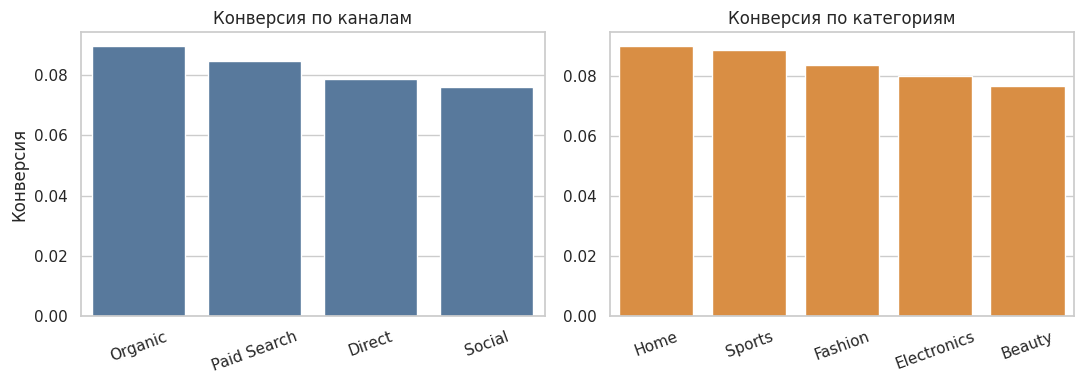

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=channel_metrics, x="acquisition_channel", y="purchase_conversion", ax=axes[0], color="#4C78A8")
axes[0].set_title("Конверсия по каналам"); axes[0].set_xlabel(""); axes[0].set_ylabel("Конверсия")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=category_metrics, x="category", y="purchase_conversion", ax=axes[1], color="#F28E2B")
axes[1].set_title("Конверсия по категориям"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## Основные наблюдения

- До покупки дошли **351 из 4 200 сессий** — конверсия составила **8,4%**.
- Самая большая потеря — между просмотром товара и добавлением в корзину: **2 144 сессии**, или **71,6%** от сессий с просмотром товара.
- Конверсия в покупку на десктопе — **11,8%**, на мобильных устройствах — **7,0%**. Разница составляет около **4,9 п.п.**
- Среди каналов в этой выборке выше конверсия у Organic (**9,0%**), ниже — у Social (**7,6%**).

Логичный следующий шаг — отдельно изучить карточку товара и сценарий добавления в корзину на мобильных устройствах: проверить ошибки, скорость загрузки и доступность ключевых элементов. Это направление для проверки, а не установленная причина потерь.


In [10]:
overall_conversion = funnel.loc[funnel.event_name.eq("purchase_completed"), "conversion_from_search"].iloc[0]
print(f"Конверсия сессии в покупку: {overall_conversion:.1%}")
print("Самая большая потеря сессий:", worst_step.step)
print("Разница в purchase conversion между устройствами:", f"{(device_metrics.purchase_conversion.max()-device_metrics.purchase_conversion.min())*100:.1f} п.п.")

Конверсия сессии в покупку: 8.4%
Самая большая потеря сессий: Добавление в корзину
Разница в purchase conversion между устройствами: 4.9 п.п.


## Ограничения

- Данные синтетические и не описывают реальный маркетплейс.
- Анализ ведётся на уровне сессий, а не уникальных пользователей.
- Для воронки используется наличие события в сессии; повторные действия и временные интервалы между шагами отдельно не исследуются.
- Сегментные различия описательные и не доказывают причинность.
- В данных нет событий об ошибках поиска, качестве выдачи, доступности товара и сбоях на чекауте.
